In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv(r"C:\Users\HP\Downloads\playstore_fraud_detection_practice_dataset.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully
Shape: (20, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor Pro,PHOTOGRAPHY,4.6,125430.0,35M,"10,000,000+",Free,0.0,Everyone,Photography,2026-08-12,5.2.1,8.0 and up
1,Quick Notes,PRODUCTIVITY,4.2,18450.0,12M,"1,000,000+",Free,0.0,Everyone,Productivity,2026-07-30,2.4.0,7.0 and up
2,Super Racing 3D,GAME,4.8,983210.0,88M,"50,000,000+",Free,0.0,Everyone,Racing,2026-08-01,9.1.2,9.0 and up
3,Daily Fitness,HEALTH_AND_FITNESS,4.1,8700.0,24M,"500,000+",Free,0.0,Everyone,Health & Fitness,2026-06-22,3.0.1,8.0 and up
4,Budget Planner,FINANCE,4.4,21300.0,18M,"1,000,000+",Free,0.0,Everyone,Finance,2026-08-05,4.6.0,8.0 and up


In [3]:
print("Number of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Number of rows and columns:
(20, 13)

Column names:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Data types:
App                   str
Category              str
Rating            float64
Reviews           float64
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             20 non-null     str    
 1   Category        20 non-null     str    
 2   Rating          19 non-null     float64
 3   Reviews         19 non-null     float64
 4   Size            20 non-null     str    
 5

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,20,19,Photo Editor Pro,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,20,13,TOOLS,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,19.0,NaN,NaN,NaN,4.431579,0.328384,3.8,4.2,4.5,4.65,5.0
Reviews,19.0,NaN,NaN,NaN,114449.315789,237326.533704,0.0,7700.0,21300.0,94715.0,983210.0
Size,20,19,35M,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,20,11,"1,000,000+",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,20,2,Free,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,20,4,0.0,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,20,2,Everyone,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,20,14,Tools,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nMissing value percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

Missing values in each column:
App               0
Category          0
Rating            1
Reviews           1
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

Total missing values:
2

Missing value percentage:
App               0.0
Category          0.0
Rating            5.0
Reviews           5.0
Size              0.0
Installs          0.0
Type              0.0
Price             0.0
Content Rating    0.0
Genres            0.0
Last Updated      0.0
Current Ver       0.0
Android Ver       0.0
dtype: float64


In [5]:
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Updated dataset shape:", df.shape)

Duplicate rows before cleaning: 1
Duplicate rows after cleaning: 0
Updated dataset shape: (19, 13)


In [6]:
df.columns = df.columns.str.strip()

text_columns = df.select_dtypes(include=["str", "object"]).columns

for col in text_columns:
    df[col] = df[col].str.strip()

print("Column names and text values cleaned.")
display(df.head())

Column names and text values cleaned.


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor Pro,PHOTOGRAPHY,4.6,125430.0,35M,"10,000,000+",Free,0.0,Everyone,Photography,2026-08-12,5.2.1,8.0 and up
1,Quick Notes,PRODUCTIVITY,4.2,18450.0,12M,"1,000,000+",Free,0.0,Everyone,Productivity,2026-07-30,2.4.0,7.0 and up
2,Super Racing 3D,GAME,4.8,983210.0,88M,"50,000,000+",Free,0.0,Everyone,Racing,2026-08-01,9.1.2,9.0 and up
3,Daily Fitness,HEALTH_AND_FITNESS,4.1,8700.0,24M,"500,000+",Free,0.0,Everyone,Health & Fitness,2026-06-22,3.0.1,8.0 and up
4,Budget Planner,FINANCE,4.4,21300.0,18M,"1,000,000+",Free,0.0,Everyone,Finance,2026-08-05,4.6.0,8.0 and up


In [7]:
# Convert reviews to numeric
df["Reviews"] = pd.to_numeric(df["Reviews"], errors="coerce")

# Convert installs such as "1,000+" into numbers
df["Installs"] = pd.to_numeric(
    df["Installs"].astype(str)
      .str.replace(",", "", regex=False)
      .str.replace("+", "", regex=False),
    errors="coerce"
)

# Convert price such as "$4.99" into numbers
df["Price"] = pd.to_numeric(
    df["Price"].astype(str)
      .str.replace("$", "", regex=False),
    errors="coerce"
)

# Convert app size to megabytes
def convert_size(value):
    value = str(value).strip()

    if value in ["nan", "NaN", "Varies with device", ""]:
        return np.nan

    try:
        if value.endswith("M"):
            return float(value[:-1])
        elif value.endswith("k"):
            return float(value[:-1]) / 1024
        else:
            return np.nan
    except ValueError:
        return np.nan

df["Size_MB"] = df["Size"].apply(convert_size)

print(df[["Reviews", "Installs", "Price", "Size_MB"]].dtypes)
display(df[["App", "Reviews", "Installs", "Price", "Size_MB"]].head())

Reviews     float64
Installs      int64
Price       float64
Size_MB     float64
dtype: object


,App,Reviews,Installs,Price,Size_MB
0,Photo Editor Pro,125430.0,10000000,0.0,35.0
1,Quick Notes,18450.0,1000000,0.0,12.0
2,Super Racing 3D,983210.0,50000000,0.0,88.0
3,Daily Fitness,8700.0,500000,0.0,24.0
4,Budget Planner,21300.0,1000000,0.0,18.0


In [8]:
# Ratings should be between 0 and 5
df.loc[~df["Rating"].between(0, 5), "Rating"] = np.nan

# Negative values are invalid for these columns
for col in ["Reviews", "Installs", "Price", "Size_MB"]:
    df.loc[df[col] < 0, col] = np.nan

# Remove rows with missing app names or categories
df = df.dropna(subset=["App", "Category"]).copy()

print("Invalid values handled.")
print("Missing values now:")
print(df.isnull().sum())

Invalid values handled.
Missing values now:
App               0
Category          0
Rating            1
Reviews           1
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
Size_MB           1
dtype: int64


In [9]:
# Remove rows where the target rating is missing
df = df.dropna(subset=["Rating"]).copy()

# Fill missing categorical values
for col in ["Category", "Type", "Content Rating", "Genres"]:
    if col in df.columns:
        mode_value = df[col].mode(dropna=True)

        if not mode_value.empty:
            df[col] = df[col].fillna(mode_value.iloc[0])

# Fill missing numerical values
for col in ["Reviews", "Installs", "Price", "Size_MB"]:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after handling:")
print(df.isnull().sum())

print("\nRemaining missing values:", df.isnull().sum().sum())

Missing values after handling:
App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
Size_MB           0
dtype: int64

Remaining missing values: 0


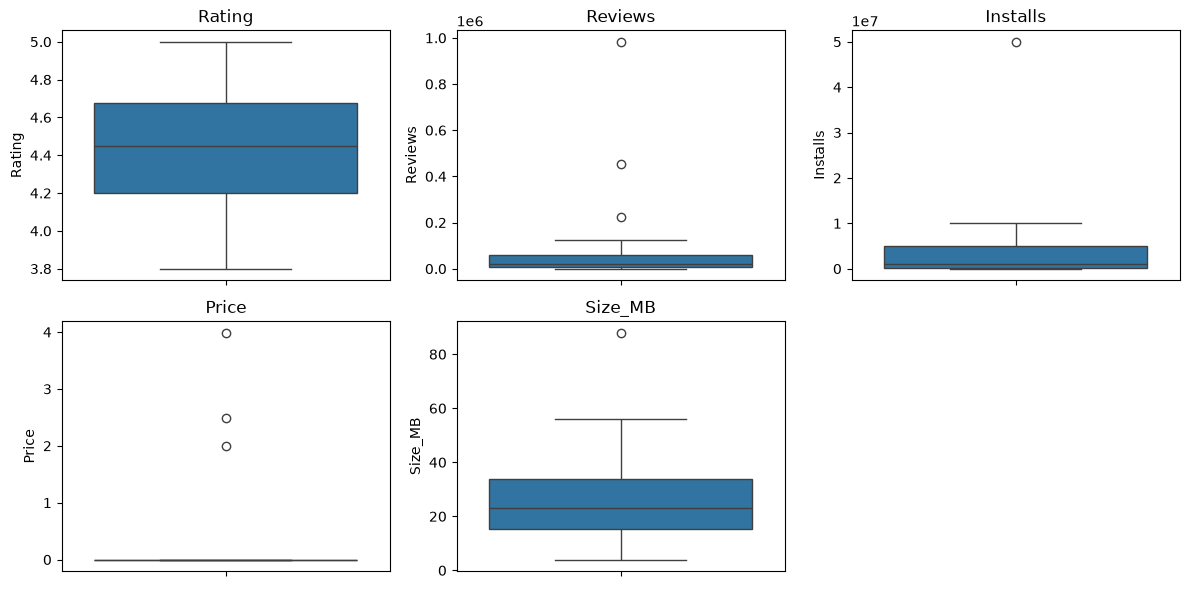

In [10]:
numeric_columns = ["Rating", "Reviews", "Installs", "Price", "Size_MB"]

plt.figure(figsize=(12, 6))

for i, col in enumerate(numeric_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [11]:
outlier_columns = ["Reviews", "Installs", "Price", "Size_MB"]

for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(f"\nColumn: {col}")
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of potential outliers:", len(outliers))


Column: Reviews
Lower limit: -68762.5
Upper limit: 138537.5
Number of potential outliers: 3

Column: Installs
Lower limit: -7000000.0
Upper limit: 12200000.0
Number of potential outliers: 1

Column: Price
Lower limit: 0.0
Upper limit: 0.0
Number of potential outliers: 3

Column: Size_MB
Lower limit: -12.875
Upper limit: 62.125
Number of potential outliers: 1


In [12]:
df_clean = df.copy()

for col in outlier_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = max(0, Q1 - 1.5 * IQR)
    upper_limit = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outlier capping completed.")
display(df_clean[outlier_columns].describe().T)

Outlier capping completed.


,count,mean,std,min,25%,50%,75%,max
Reviews,18.0,4.593386e+04,5.192905e+04,3.0,8975.00,21300.0,60800.0,1.385375e+05
Installs,18.0,3.242283e+06,4.305464e+06,100.0,200000.00,1000000.0,5000000.0,1.220000e+07
Price,18.0,0.000000e+00,0.000000e+00,0.0,0.00,0.0,0.0,0.000000e+00
Size_MB,18.0,2.622917e+01,1.597437e+01,4.0,15.25,23.0,34.0,6.212500e+01


In [13]:
df_model = df_clean.copy()

df_model["Log_Reviews"] = np.log1p(df_model["Reviews"])
df_model["Log_Installs"] = np.log1p(df_model["Installs"])

features = [
    "Log_Reviews",
    "Log_Installs",
    "Price",
    "Size_MB"
]

X = df_model[features]
y = df_model["Rating"]

print("Input features:")
display(X.head())

print("\nTarget variable:")
display(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Input features:


,Log_Reviews,Log_Installs,Price,Size_MB
0,11.739511,16.118096,0.0,35.000
1,9.822874,13.815512,0.0,12.000
2,11.838904,16.316947,0.0,62.125
3,9.071193,13.122365,0.0,24.000
4,9.966509,13.815512,0.0,18.000



Target variable:


0    4.6
1    4.2
2    4.8
3    4.1
4    4.4
Name: Rating, dtype: float64


Feature shape: (18, 4)
Target shape: (18,)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (14, 4)
Testing features: (4, 4)
Training target: (14,)
Testing target: (4,)


In [15]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

print("Multiple Linear Regression model trained successfully.")

Multiple Linear Regression model trained successfully.


In [16]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": y_pred
})

display(results.head(10))

,Actual Rating,Predicted Rating
0,4.6,4.315293
1,4.2,4.158427
2,4.5,4.607200
3,4.7,4.480841


In [17]:
r2 = r2_score(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("R² Score:", round(r2, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))

R² Score: -0.0165
Mean Squared Error (MSE): 0.0356
Root Mean Squared Error (RMSE): 0.1886


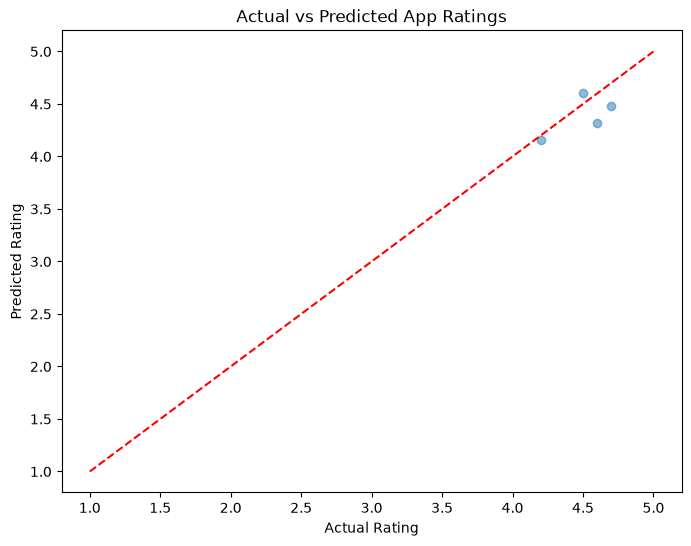

In [18]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted App Ratings")

plt.plot([1, 5], [1, 5], "r--")

plt.show()

In [19]:
regression_model = model.named_steps["regression"]

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": regression_model.coef_
})

display(coefficients)

print("Intercept:", regression_model.intercept_)

,Feature,Coefficient
0,Log_Reviews,-0.118833
1,Log_Installs,0.022575
2,Price,0.000000
3,Size_MB,0.014463


Intercept: 4.840262714036561


In [22]:
df_clean.to_csv("googleplaystore_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [23]:
import os

print(os.path.abspath("googleplaystore_cleaned.csv"))

C:\Users\HP\googleplaystore_cleaned.csv
